# Integrated Intelligent Systems: Tutorial 3 - Body Motion Problem (Scientific Object) (3 Pts)

This notebook introduces a formulation body motion problem, central to designing and implementing Cognition-Enabled Robot Agents, as a description logic system.

## Part 1: Robot-World Manipulation System as Scientific Object (E1–E6) (1.5 Pt)

**Title:** Formalizing the Robot Agent: From Architecture to Description Logic Reasoners

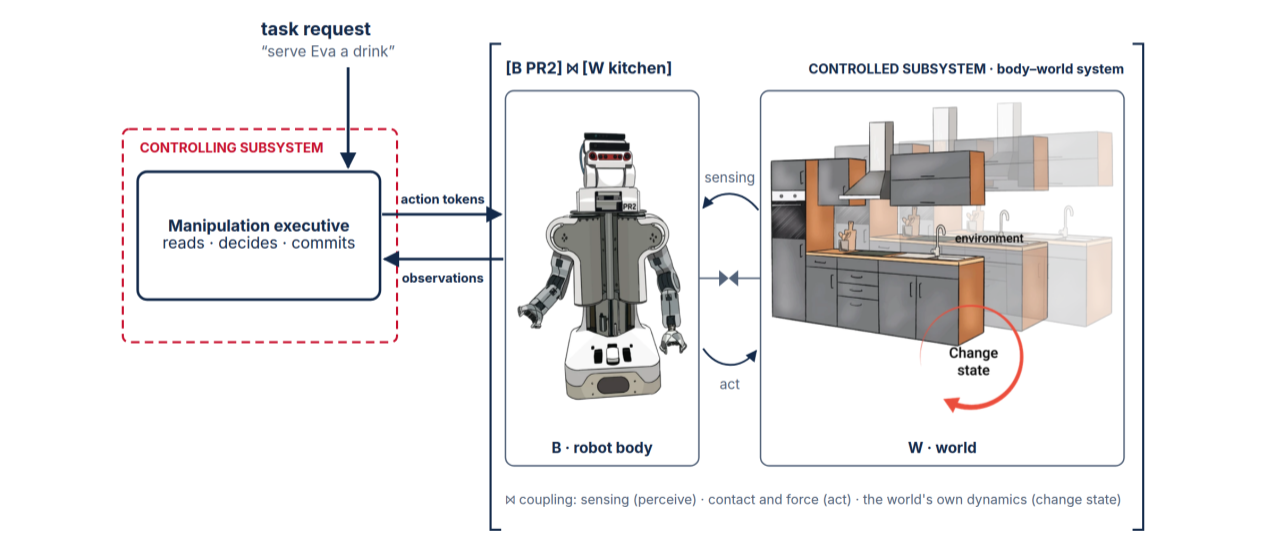
### Scenario Background
An autonomous robotic agent (the PR2 in the EASE apartment) is deployed to execute a manipulation task ("Serve Eva a drink"). To validate this agent scientifically, we must formalize the system as a **Robot-World Manipulation System (RWMS)**, separate the controlling subsystem from the controlled body-world system, define trajectories as trees, and assess runs against an external problem standard using a description logic reasoner.

---

### Multi-Question Student Task Sheet (0.25 Pt x 6)

1. **E1 · Architectural Cut & Subsystem Separation**
   - In the graphical representation of the RWMS, a strict architectural "cut" is placed between the manipulation executive and the body-world system ($[B \bowtie W]$). Explain the nature of this cut: why is the manipulation executive classified as a `dul:Agent` (non-physical program) while the body-world system is classified under physical objects, and how do they interact exclusively across the boundary?

2. **E2 · Forward-Branching Time & World Choices**
   - During an operation on a fridge door or container seal, the same action token (e.g., a position-controlled pull) can lead to completely divergent physical outcomes depending on world choices (e.g., seal releases vs. seal holds tight). Draw or describe the structure of the resulting courses, and explain why the possible courses form a tree that branches *only forward* from the initial state $x_0$.

3. **E3 · Trajectory Classification & Priority Hierarchies**
   - The problem standard $P$ sorts every physical trajectory into one of four classes: **SOL** (Solution), **REPD** (Repaired), **NON** (Nonachievement), and **PROH** (Prohibited). Consider two runs that both successfully place the drink within Eva's reach, but where Run A tears off the container handle (`P4` violation) while Run B maintains licensed contact. Classify both runs and explain why the classifier grades the *entire course* rather than just the final end-state.

4. **E4 · Description Logic Partonomy & DUL Constraints**
   - When formalizing the RWMS in description logic under DOLCE Ultra Lite (DUL), we define an RWMS as having *exactly one* executive and *exactly one* body-world system (`RWMS = (=1 hasComponent.ManipExecutive) ⊓ (=1 hasComponent.BodyWorldSystem)`). Using the transitivity of `dul:isPartOf`, explain how a reasoner (such as HermiT) automatically entails that the PR2's head camera is a component of the RWMS without explicitly hardcoding every part-whole link.

5. **E5 · Ontological Inconsistency & Entailment Limits**
   - An inconsistency in description logic serves as a strict analytical tool. Formulate a competency question that results in an ontological inconsistency when attempting to classify the *manipulation problem itself* as a physical component inside the RWMS. Furthermore, explain why numerical physical laws (such as Coulomb friction $2 \cdot \mu \cdot F \ge m \cdot (g + a)$) must be handled outside description logic by the semantic digital twin's causal model.

6. **E6 · Strength vs. Truth in Agent Validation**
   - The design thesis dictates that an agent decides within its believed causality, which can be tested for logical *strength* via competency queries and for *truth* via physical experiments. Compare how an axiom set that lacks a friction law ($\text{K}_0$) performs on competency queries versus an axiomatization containing explicit dynamical laws ($\text{K}_1/\text{K}_2$), and state what kind of test is required to validate the actual physical truth of those beliefs.


## Student Answers – Part 1 (E1–E6)

### E1 · Architectural Cut & Subsystem Separation

The architectural cut separates the software that decides what to do from the physical system that carries it out. The manipulation executive is modelled as a `dul:Agent` because it is a program: it represents the decision-making and control process, not a physical object occupying space. The body-world system, `[B ⋈ W]`, contains the physical robot body and the environment with which it interacts, so it is classified under physical objects. They interact across the boundary through commands or action descriptions sent from the executive to the body, and observations or state information returned from the body-world system to the executive. This separation makes it possible to describe the agent's reasoning independently of the physical realization of its actions.

### E2 · Forward-Branching Time & World Choices

The possible courses can be represented as a tree whose root is the initial state `x₀`. From `x₀`, the robot performs an action, such as a position-controlled pull. Different possible world responses can then produce different successor states: for example, one branch represents the seal releasing, while another represents the seal remaining stuck. Each successor can itself have further possible actions and outcomes. The courses share the same history up to the point where their outcomes diverge. The tree branches only forward because the initial state and past events are fixed; uncertainty concerns which future outcome follows, not alternative versions of an already completed past.

### E3 · Trajectory Classification & Priority Hierarchies

Run A is **PROH (Prohibited)** because tearing off the container handle violates constraint `P4`, even though the drink reaches Eva. Run B is **SOL (Solution)**, assuming it achieves the requested placement and respects the licensed-contact constraints throughout the run. The classifier must evaluate the entire physical course, not only the final state, because actions along the way can cause damage or violate safety and interaction constraints. A successful end-state does not make an otherwise prohibited trajectory acceptable.

### E4 · Description Logic Partonomy & DUL Constraints

The RWMS definition requires exactly one manipulation executive and exactly one body-world system. The body-world system contains the PR2, and the PR2 contains parts such as its head and head camera. If the relevant part-whole relations are represented using `dul:isPartOf`, its transitivity allows the reasoner to chain the relations: the camera is part of the PR2 head, the head is part of the PR2, and the PR2 is part of the body-world system, which is part of the RWMS. The reasoner can therefore infer the camera's indirect part-of relationship to the RWMS without separately writing every possible transitive link. This conclusion depends on the corresponding component/part relations being asserted and aligned with the DUL modelling.

### E5 · Ontological Inconsistency & Entailment Limits

A suitable competency question is: **“Is the manipulation problem itself a physical component of this RWMS?”** To make an attempted classification inconsistent, the ontology must distinguish abstract problems from physical components, for example, by making `ManipulationProblem` disjoint with `PhysicalComponent` (or the relevant physical-object class). Asserting that the same manipulation problem is both an instance of `ManipulationProblem` and a physical component then violates that disjointness axiom, and a description-logic reasoner reports the ontology as inconsistent.

Description logic is suited to class membership, relations, and logical constraints, but ordinary description-logic reasoning does not solve numerical contact-dynamics inequalities such as `2 · μ · F ≥ m · (g + a)`. It does not by itself calculate the values and changing physical quantities needed to predict slipping. Those numerical and causal calculations belong in the semantic digital twin's causal/physics model, which can supply results to the symbolic reasoning layer.

### E6 · Strength vs. Truth in Agent Validation

An axiom set `K₀` without a friction law has limited logical strength for questions that depend on friction: the reasoner cannot derive whether a grasp is physically sufficient from a friction condition that is absent. An enriched axiomatisation such as `K₁/K₂`, when it includes explicit dynamical laws, can support more competency-query conclusions because more relevant relationships and constraints are represented. However, a larger set of axioms only increases what can be derived from the model; it does not prove that those axioms correctly describe the real world. The actual physical truth of the agent's beliefs must be tested through physical experiments, measuring the relevant quantities and comparing observed outcomes with the model's predictions.


## Part 2: Robot Motion Problem and Description Logics (1.5 Pt)

**Title:** Formulating and Querying the Robot Motion Problem with Knowledge Bases & Description Logics

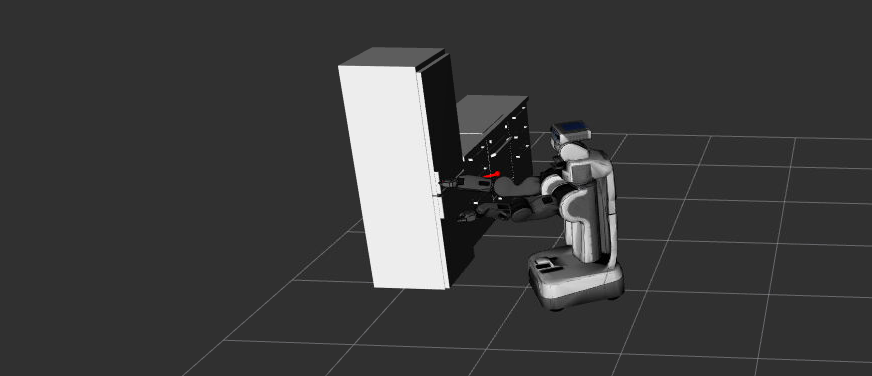
### Scenario Background
Using the interactive Jupyter notebook and RViz simulation environment (`bmp.rviz`, `setup_demo()`), the PR2 mobile manipulator interacts with the EASE apartment model (including the fridge and various kitchen drawers). Instead of hardcoding trajectories, the robotic executive queries a knowledge base (represented via Description Logics / Prolog reasoning) to link task requests to state changes, causes (motions), and capabilities.

[Go to the programming Lab](https://binder.intel4coro.de/v2/gh/maltehue/giskard-examples/bmp_vrb?urlpath=/lab/tree/notebooks/bodyMotionProblem.ipynb)
---

### Multi-Question Student Task Sheet (0.25 Pt x 6)

1. **E7 · Knowledge Base Grounding & Task Requests**
   - Execute the initial query `taskRequest(Request, StateChange).`Examine the resulting solution bindings (e.g., `{'Request': 'open_fridge', 'StateChange': 'open(fridge)'}` and various drawer operations). Explain how mapping abstract task requests to discrete state changes forms the top-level specification layer for the manipulation executive.

2. **E8 · Extending Queries for Causal Motions & Parameters**
   - Extend the query to incorporate motion causes: `taskRequest(Request, StateChange), causes(Motion, StateChange, MotionParam).` Explain how the reasoner bridges the gap between a desired symbolic state change and continuous motion parameters (such as `envJointGoal`, target joint angles, and handle identifiers).

3. **E9 · Integrating Robot Capabilities (`canPerform`)**
   - Finalize the query by adding the robot capability constraint: `taskRequest(Request, StateChange), causes(Motion, StateChange, MotionParam), canPerform(Robot, Motion, MotionParam).`Describe what role the `Robot` variable (`'pr2'`) plays in filtering feasible trajectories through the reasoner.

4. **E10 · Specializing Request Scope (`open_fridge` vs. `open_anything`)**
   - Modify the query request parameter from general categories like `open_anything` to specifically target `open_fridge`. Explain how refining the scope in the knowledge base reduces the solution search tree and prevents unauthorized or unintended state changes in the kitchen environment.

5. **E11 · Visualization and Simulation Linkage in RViz**
   - With the background shell command executing `rviz -d .../bmp.rviz` and displaying the PR2 interacting with the fridge handle, explain how the motion parameters derived from the reasoner's output (`[0.8, b'fridge_door_joint', b'fridge_door_handle']`) are executed as physical joint trajectories in the simulation.

6. **E12 · Ontological Limits & Missing Dynamics**
   - While the knowledge base successfully infers *which* motion achieves a state change, explain why a pure Description Logic or symbolic Prolog reasoner cannot verify whether a specific grasp force will cause a wet carton to slip, and identify which subsystem must handle those physical calculations.


## Student Answers – Part 2 (E7–E12)

### E7 · Knowledge Base Grounding & Task Requests

The query taskRequest(Request, StateChange). returns 17 solutions: open_fridge maps to open(fridge), open_anything maps to opening the fridge, the oven drawer and drawer_01 to drawer_06, and close_anything maps to closing the same objects. This is the top-level specification layer: the executive starts from a task request and gets the symbolic state change that would achieve it. No robot motion is selected yet.
![Robot Opening Door](Robot%20Opening%20Door.png)


### E8 · Extending Queries for Causal Motions & Parameters

Adding causes(Motion, StateChange, MotionParam) reduces the results from 17 to 9. Only the open(...) state changes get a motion, envJointGoal, with a target joint value and handle, e.g. [0.8, fridge_door_joint, fridge_door_handle] for the fridge and [0.2, drawer_06_joint, drawer_06_handle] for drawers. The close(...) state changes disappear because the knowledge base has no causes rule for them. So causes bridges a symbolic effect to a parameterised motion, but only where such knowledge was written down.
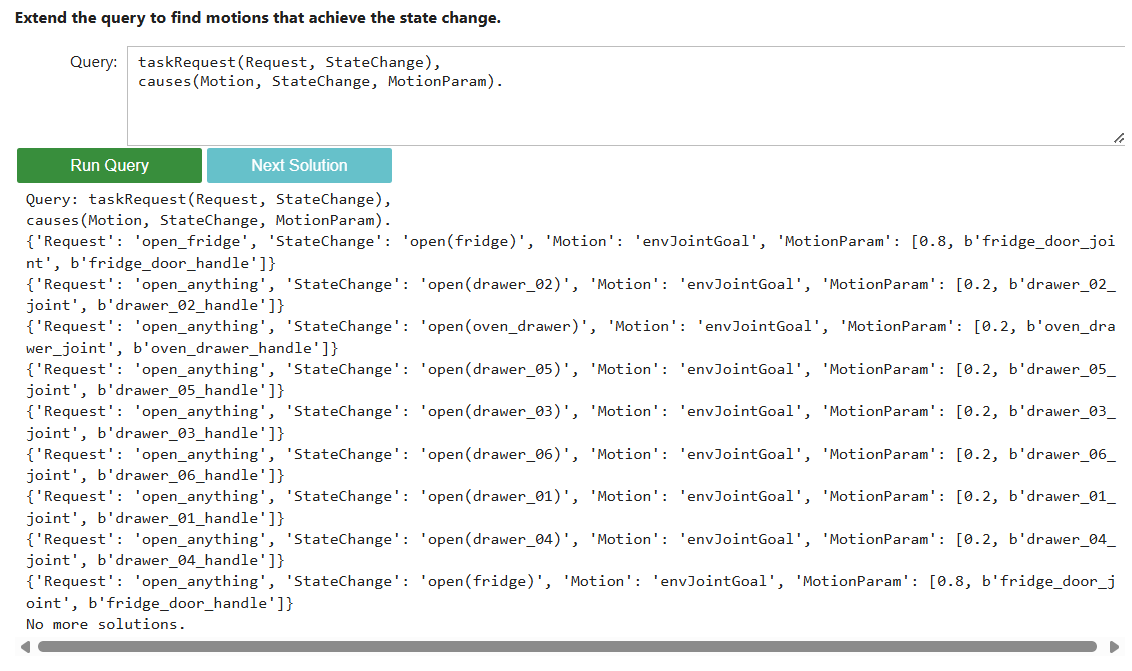

### E9 · Integrating Robot Capabilities (`canPerform`)

Adding canPerform(Robot, Motion, MotionParam) binds Robot = pr2 for every solution and keeps only combinations the robot is known to be able to perform. Every solution appears twice (18 rows for 9 distinct combinations), so there are duplicate derivations, not 18 different motions.

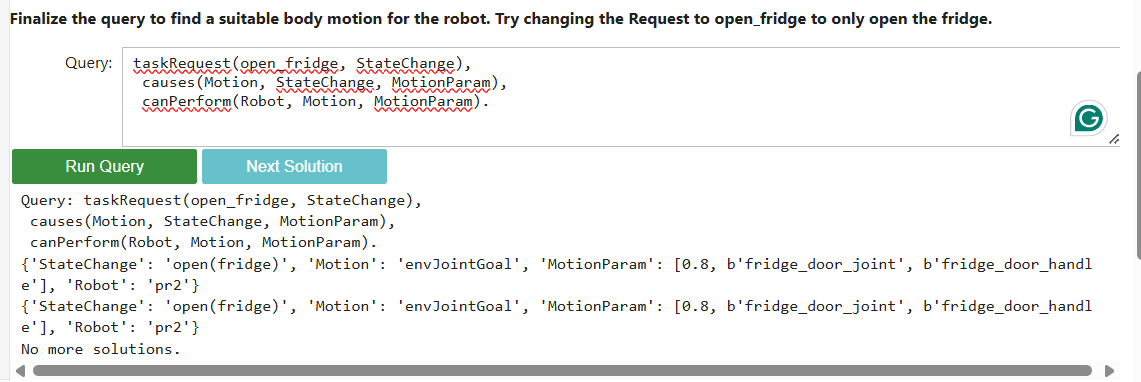

### E10 · Specializing Request Scope (`open_fridge` vs. `open_anything`)

A general request such as `open_anything` can produce solutions for several objects, including drawers and the fridge. To restrict the query to the fridge, replace the variable `Request` with the constant `open_fridge`:

```prolog
taskRequest(open_fridge, StateChange),
causes(Motion, StateChange, MotionParam),
canPerform(Robot, Motion, MotionParam).
```

This binds the request to the specific task and narrows the search to the state change and motion associated with opening the fridge. It avoids returning drawer-opening alternatives that are valid for the broader `open_anything` request. The final query output pasted before this answer still includes `open_anything` solutions, so this specialized query must be run to demonstrate the requested filtering. A narrower request reduces unintended alternatives in the reasoning result; it does not, by itself, establish a complete authorization or safety policy.

### E11 · Visualization and Simulation Linkage in RViz

For the fridge-opening result, the reasoner returns the motion `envJointGoal` with parameters `[0.8, fridge_door_joint, fridge_door_handle]`. These parameters identify the target joint configuration and the interaction handle. The motion-execution component can use this specification to generate and execute a joint trajectory for the simulated PR2, while RViz displays the robot and the resulting motion in the EASE apartment scene. The knowledge-base query supplies the symbolic motion choice and its parameters; the simulation and motion-control components perform and visualize the physical movement. The query output alone does not prove that the trajectory executed successfully, so the RViz result should be checked and, if required by the course, captured as a screenshot.
![Robot Opening Door.png](<attachment:Robot Opening Door.png>)

### E12 · Ontological Limits & Missing Dynamics

The symbolic knowledge base can infer which motion is associated with a desired state change, but a pure description-logic or symbolic Prolog reasoner cannot determine from these facts alone whether a grasp force will prevent a wet carton from slipping. That prediction requires numerical physical quantities and a model of contact dynamics, including friction, normal force, mass, acceleration, and relevant contact conditions. Those calculations must be handled by the semantic digital twin's causal/physical model rather than by the symbolic task-and-capability rules alone.

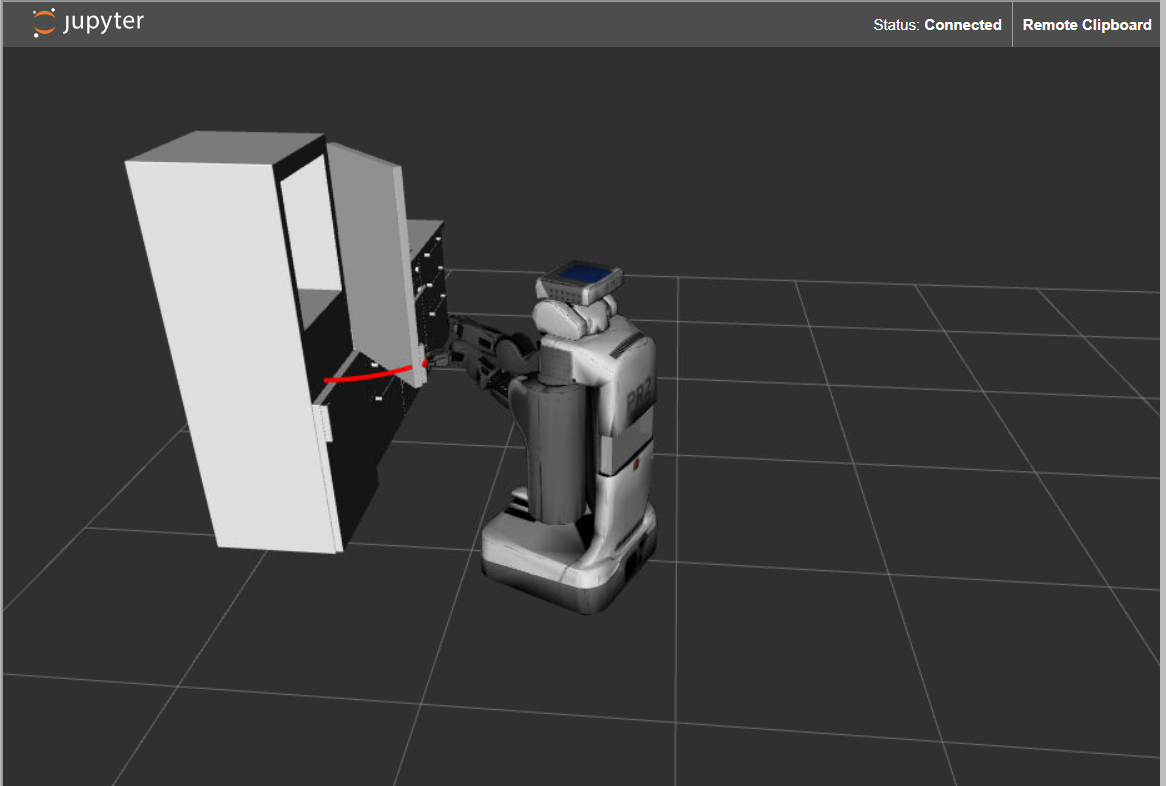